# Step 2: Build the Working Dataset

**BT4222 Final Project, Group 13, JDSearch**

Step 1 measured the timeline of the raw log. Step 2 turns the two raw files into the four tables that every later step reads, for a **fixed, seeded sample of 20,000 users**, and decides the train / validation / test split **once**. Nothing after this step is allowed to change who is in which split.

## How to read this notebook

Every code cell is cut verbatim from `src/step2_build_dataset.py`, so the notebook and the script cannot drift apart
(`tests/test_notebooks.py` checks it). Each cell is preceded by a short explanation of what it does and
why, and the table below links every section to the function that implements it and to the file it
produces, so any number in the report can be traced back to a cell.

* **Part A** rebuilds the step. It needs the inputs listed below.
* **Part B** reads the measured outputs of the corrected run (`artifacts/corrected`) and re-checks them.
  It needs no raw data, so it always runs and its outputs are saved in this copy of the notebook.

| Section | What it does | Code in `src/step2_build_dataset.py` | Writes |
|---|---|---|---|
| A.1 | Sample size | `main()` | - |
| A.2 | Parse, validate and split (`build_records`) | `build_records` | - |
| A.3 | Draw the 20,000 sampled rows | `main()` | - |
| A.4 | Build candidates, history, sessions, split | `build_records` | in memory |
| A.5 | Keep only the metadata of referenced products | `main()` | in memory |
| A.6 | Save tables and the dataset manifest | `main()` | `candidates`, `history`, `sessions`, `meta_subset` (`.parquet`), `dataset_manifest.json` |
| B.1 | Read the manifest of the corrected run | - | - |
| B.2 | Re-check the split fingerprint, describe sessions | - | - |

**Inputs.** Raw `user_behavior_data.txt` (957 MB) and `product_meta_data.txt` (4.8 GB) from the official [JDSearch release](https://github.com/rucliujn/JDsearch). They are not in the repository.

**Outputs.** `candidates.parquet`, `history.parquet`, `sessions.parquet`, `meta_subset.parquet` in the model folder of the run directory, and `dataset_manifest.json`.

## What the four tables are

One raw row is one search session: the current `query`, the **candidate slate** with a graded label for
each product (0 none, 1 click, 2 cart, 3 purchase) and the user's **preceding history** as parallel lists
(`history_wid_list`, `history_type_list`, `history_qry_list`) plus `history_time_list`, which holds n+1
time gaps for n events (Step 1 explains how they become "days before the query").

| Table | One row per | Key columns |
|---|---|---|
| `candidates` | (session, candidate product) | `session_id`, `query`, `cand_wid`, `label` |
| `history` | (session, past event) | `session_id`, `pos`, `wid`, `type`, `qry`, `elapsed_days` |
| `sessions` | session | `session_id`, `source_row_id`, `query`, `slate_size`, `n_hist`, `split` |
| `meta_subset` | referenced product | raw metadata: `name`, `brand_id`, `brand_name`, `cate_id_1` to `cate_id_4`, `cate_name_*`, ... |

**Design decisions made here, and why they matter later**

1. **Complete histories.** The draft capped each history at 60 events, which hid the oldest orders, the
   very events Step 1 shows are the only ones that survive beyond 90 days. Here every preceding event is kept.
2. **Split by user, once.** A seeded permutation assigns 70% / 15% / 15% of the sessions to train /
   validation / test. Each user appears in exactly one split, and a SHA-256 fingerprint of the membership
   is stored in the manifest.
3. **Fail loudly.** Misaligned lists, duplicated candidates, unknown action types or labels outside 0 to 3
   raise an error instead of producing a silently wrong table.
4. **Real metadata names.** The metadata subset must contain `name`, `cate_name_3` and `brand_name`; ids
   alone are not enough for the query-to-product matching features of Step 3.

## 0. Environment setup

The first cell finds the project and puts `src/` on `sys.path`, so `config`, `data_utils`
and `eval_utils` can be imported exactly as the scripts do.

* **In Colab** it clones the repository (branch set in `BRANCH`). Set `MOUNT_DRIVE = True` if the
  raw files live on Google Drive: raw paths and the output folder then point to Drive, so the
  outputs of one step survive until the next notebook.
* **Locally** it looks for `Final Project/` next to the notebook.
* All paths come from environment variables read by `src/config.py`:
  `JD_USER_TXT`, `JD_PRODUCT_TXT` (raw files), `JD_RUN_DIR` (where outputs are written, default
  `artifacts/corrected`), `JD_SEED` (default 42).

In [1]:
# Optional: install dependencies in a fresh environment (Colab already has most of them)
# !pip -q install numpy pandas pyarrow scipy scikit-learn lightgbm joblib matplotlib torch

import os, sys, subprocess
from pathlib import Path

REPO_URL = "https://github.com/steffanylars/nus-web-mining-business-insights.git"
BRANCH = "steff-coldstart-diversity"   # change to the team's final branch before submission
MOUNT_DRIVE = False                    # Colab only: True keeps raw data and outputs on Google Drive
DRIVE_DIR = "/content/drive/MyDrive/JDsearch"

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    if MOUNT_DRIVE:
        from google.colab import drive
        drive.mount("/content/drive")
        os.environ.setdefault("JD_USER_TXT", f"{DRIVE_DIR}/user_behavior_data.txt")
        os.environ.setdefault("JD_PRODUCT_TXT", f"{DRIVE_DIR}/product_meta_data.txt")
        os.environ.setdefault("JD_RUN_DIR", f"{DRIVE_DIR}/runs/corrected")
    repo = Path("/content/nus-web-mining-business-insights")
    if not (repo / ".git").exists():
        subprocess.run(["git", "clone", "--branch", BRANCH, REPO_URL, str(repo)], check=True)
    PROJECT_ROOT = repo / "Final Project"
else:
    here = Path.cwd()
    options = [here, here.parent, here / "Final Project", here.parent / "Final Project"]
    PROJECT_ROOT = next((p for p in options if (p / "src" / "config.py").exists()), None)
    assert PROJECT_ROOT is not None, "open this notebook from Final Project/ or Final Project/notebooks/"

SRC = PROJECT_ROOT / "src"
if str(SRC) not in sys.path:
    sys.path.insert(0, str(SRC))
print("in Colab    :", IN_COLAB)
print("project root:", PROJECT_ROOT)
print("run dir     :", os.environ.get("JD_RUN_DIR", "<default: artifacts/corrected>"))

in Colab    : False
project root: Final Project
run dir     : <default: artifacts/corrected>


## 1. Imports and shared helpers

`config` provides the portable paths (`OUT`, `RES`, raw file locations), the seed and `save_json`.
`data_utils` provides `split_list` (underscore-separated list columns) and `elapsed_days` (the suffix
sum that turns time gaps into the age of each event). The flag cell below checks whether the raw
files exist.

In [2]:
import csv, hashlib, json, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from config import OUT, RES, SRC_USER, SRC_PRODUCT, SEED, SCHEMA_VERSION, prepare, save_json
from data_utils import split_list, elapsed_days

%matplotlib inline
prepare()
print("seed:", SEED, "| schema version:", SCHEMA_VERSION)

seed: 42 | schema version: 2


### 1.1 What can run here? (the `RUN_STEP` switch)

Part A rebuilds this step and Part B reads the measured outputs, so the switch below decides whether
Part A runs.

* Part A runs only if its **inputs exist**, and it will not overwrite the committed evidence in
  `artifacts/corrected` unless you explicitly allow it (`ALLOW_OVERWRITE`). In Colab the clone is
  disposable, so overwriting is allowed by default; locally, point `JD_RUN_DIR` at a new folder.
* If Part A is skipped, nothing fails: **Part B always runs** and shows the saved results.

In [3]:
COMMITTED = (PROJECT_ROOT / "artifacts" / "corrected").resolve()
ALLOW_OVERWRITE = IN_COLAB      # a Colab clone is disposable; locally keep the committed evidence safe
HAS_INPUTS = SRC_USER.exists() and SRC_PRODUCT.exists()
RUN_STEP = HAS_INPUTS and (RES.resolve() != COMMITTED or ALLOW_OVERWRITE)

print("inputs found    :", HAS_INPUTS)
print("outputs go to   :", RES)
print("RUN_STEP        :", RUN_STEP)
if not RUN_STEP:
    why = ("required inputs not found: user_behavior_data.txt and product_meta_data.txt (set JD_USER_TXT / JD_PRODUCT_TXT)" if not HAS_INPUTS else
           "outputs would overwrite artifacts/corrected; set JD_RUN_DIR to a new folder or ALLOW_OVERWRITE = True")
    print("Part A is skipped here (" + why + ").")
    print("Part B below shows the measured outputs saved in", RES)

inputs found    : False
outputs go to   : Final Project/artifacts/corrected
RUN_STEP        : False
Part A is skipped here (required inputs not found: user_behavior_data.txt and product_meta_data.txt (set JD_USER_TXT / JD_PRODUCT_TXT)).
Part B below shows the measured outputs saved in Final Project/artifacts/corrected


# Part A: Rebuild the dataset

### A.1 Sample size

`n_users` is the sample size. The script takes it from the command line (`run_pipeline.py --users`,
default 20,000). 20,000 users keep every later step feasible on a laptop CPU and still give about 3,000
test queries.

In [4]:
start = time.time()
n_users = 20000
if n_users < 10:
    raise ValueError('Use at least 10 users for a three-way split')
print("sample size:", n_users)

sample size: 20000


### A.2 Parse and validate a raw row (`build_records`)

The function walks the sampled raw rows and builds the three per-session tables. For each row it:

1. splits the list columns on `_` and checks that candidates, labels, history ids, types and queries are aligned;
2. rejects duplicate candidates, unknown action types and labels outside 0 to 3;
3. converts the n+1 time gaps into the age in days of each event with `elapsed_days`;
4. appends one row per candidate, one per history event and one per session.

The last block assigns the split: a permutation of the sessions seeded with `SEED`, the first 70% become
train, the next 15% validation and the rest test.

In [5]:
def build_records(records, selected):
    candidates, histories, sessions = [], [], []
    selected = set(selected)
    sid = 0
    for source_row, row in enumerate(records):
        if source_row not in selected:
            continue
        cw = split_list(row['candidate_wid_list'])
        labs = [int(float(x)) for x in split_list(row['candidate_label_list'])]
        hw = split_list(row['history_wid_list'])
        ht = split_list(row['history_type_list'])
        hq = split_list(row['history_qry_list'])
        if not cw or len(cw) != len(labs) or len(set(cw)) != len(cw):
            raise ValueError(f'Invalid candidate alignment at source row {source_row}')
        if len(hw) != len(ht) or len(hw) != len(hq) or any(x not in {'CLICK','CART','ORD','FLW'} for x in ht):
            raise ValueError(f'Invalid history alignment at source row {source_row}')
        if any(x not in {0,1,2,3} for x in labs):
            raise ValueError(f'Invalid labels at source row {source_row}')
        age = elapsed_days([float(x) for x in split_list(row['history_time_list'])], len(hw))
        candidates.extend((sid,row['query'],w,lab) for w,lab in zip(cw,labs))
        histories.extend((sid,pos,w,t,q,float(d)) for pos,(w,t,q,d) in enumerate(zip(hw,ht,hq,age)))
        sessions.append((sid,source_row,row['query'],len(cw),len(hw)))
        sid += 1
    cand = pd.DataFrame(candidates, columns=['session_id','query','cand_wid','label'])
    hist = pd.DataFrame(histories, columns=['session_id','pos','wid','type','qry','elapsed_days'])
    sess = pd.DataFrame(sessions, columns=['session_id','source_row_id','query','slate_size','n_hist'])
    perm = np.random.default_rng(SEED).permutation(len(sess))
    a = int(.70*len(sess)); b = a + int(.15*len(sess))
    split = np.empty(len(sess), dtype=object)
    split[perm[:a]], split[perm[a:b]], split[perm[b:]] = 'train', 'val', 'test'
    sess['split'] = split
    return cand, hist, sess

### A.3 Draw the sampled rows

Count the rows of the raw file (minus the header) and draw `n_users` row positions with the project seed.
Sorting the positions lets the file be read once, in order.

In [6]:
if RUN_STEP:
    with SRC_USER.open('rb') as f:
        n_rows = sum(1 for _ in f)-1
    idx = np.sort(np.random.default_rng(SEED).choice(n_rows, min(n_rows,n_users), replace=False))

### A.4 Build the session tables

Stream the raw file once through `build_records`. The printout confirms how many sessions and how many
history events were kept; with complete histories the count is about three times the draft's.

In [7]:
if RUN_STEP:
    with SRC_USER.open(encoding='utf-8', newline='') as f:
        cand,hist,sess = build_records(csv.DictReader(f, delimiter='\t'), idx.tolist())
    print(f'Built {len(sess):,} users; {len(hist):,} complete history events', flush=True)

### A.5 Keep only the metadata that is referenced

The raw product file is 4.8 GB, so it is scanned line by line and only products that appear as a
candidate or in any history are kept (`refs`). The check at the end refuses to continue if the names
needed by Step 3 are missing.

In [8]:
if RUN_STEP:
    refs = set(cand.cand_wid) | set(hist.wid)
    metadata = []
    with SRC_PRODUCT.open('rb') as f:
        headers = next(f).decode('utf-8').rstrip('\r\n').split('\t')
        for line in f:
            wid = line.split(b'\t',1)[0].decode('utf-8')
            if wid in refs:
                fields = line.decode('utf-8').rstrip('\r\n').split('\t')
                if len(fields) != len(headers):
                    raise ValueError(f'Invalid metadata alignment for {wid}')
                metadata.append(fields)
    meta = pd.DataFrame(metadata, columns=headers).drop_duplicates('wid')
    if not {'cate_name_3','brand_name','name'}.issubset(meta.columns):
        raise ValueError('Raw metadata requires names as well as IDs')

### A.6 Save the tables and the manifest

Four parquet files are written to the model folder. The manifest records the seed, the counts, the split
sizes, the fingerprint of the split membership, the share of candidates with metadata and the size of
the raw files, so a later run can prove it used the same sample.

In [9]:
if RUN_STEP:
    for name,frame in [('candidates',cand),('history',hist),('sessions',sess),('meta_subset',meta)]:
        frame.to_parquet(OUT/f'{name}.parquet', index=False)
    # CRLF is fixed on purpose: pandas would otherwise use the OS line ending and the hash would differ by platform.
    membership = sess[['session_id','source_row_id','split']].to_csv(index=False, lineterminator='\r\n')
    save_json(RES/'dataset_manifest.json', dict(schema_version=SCHEMA_VERSION, seed=SEED,
        source_users=n_rows, sampled_users=len(sess), candidate_rows=len(cand), history_rows=len(hist),
        history_policy='all preceding events; independent horizon selection occurs in neural packing',
        split_counts=sess.groupby('split').size().to_dict(),
        split_sha256=hashlib.sha256(membership.encode()).hexdigest(),
        candidate_metadata_coverage=float(cand.cand_wid.isin(set(meta.wid)).mean()),
        raw_files={p.name: {'bytes':p.stat().st_size} for p in [SRC_USER,SRC_PRODUCT]}))
    print(f'Dataset ready in {OUT} ({time.time()-start:.0f}s)', flush=True)

# Part B: Measured outputs of the corrected run

Everything below reads files that Part A wrote (or, in this copy, the files committed in
`artifacts/corrected`).

### B.1 The dataset manifest

In [10]:
manifest = json.loads((RES / "dataset_manifest.json").read_text(encoding="utf-8"))
scalars = {k: v for k, v in manifest.items() if not isinstance(v, (dict, list))}
display(pd.Series(scalars, name="value").to_frame())
print("split sizes (sessions):", manifest["split_counts"])
display(pd.DataFrame(manifest["raw_files"]).T.rename(columns={"bytes": "raw file size (bytes)"}))

,value
schema_version,2
seed,42
source_users,173831
sampled_users,20000
candidate_rows,1781978
history_rows,3091153
history_policy,all preceding events; independent horizon sele...
split_sha256,012cd704c2665e7b807934f5f39da79a479ab427a083d9...
candidate_metadata_coverage,0.995498


split sizes (sessions): {'test': 3000, 'train': 14000, 'val': 3000}


,raw file size (bytes)
user_behavior_data.txt,957229589
product_meta_data.txt,4841695274


### B.2 Re-check the split and describe the sessions

The fingerprint is recomputed from `sessions.parquet` exactly as in A.6. If it equals the value stored
in the manifest, the split used by Steps 3 to 7 is provably the one decided here. (The line ending is
fixed to CRLF in both places: the original run was on Windows, where pandas writes CRLF, and an unfixed
hash would differ on Linux, macOS and Colab even for the identical split.) The plots show the
two session-level quantities the later steps depend on: slate size and history length (`n_hist`).

recomputed split fingerprint: 012cd704c2665e7b807934f5f39da79a479ab427a083d913765d618c9308f35c
matches manifest            : True
shares by split             : {'train': 0.7, 'val': 0.15, 'test': 0.15}


,slate_size,n_hist
count,20000.0,20000.0
mean,89.1,154.6
std,38.6,230.0
min,1.0,1.0
25%,77.0,28.0
50%,90.0,78.0
75%,94.2,189.0
max,200.0,4719.0


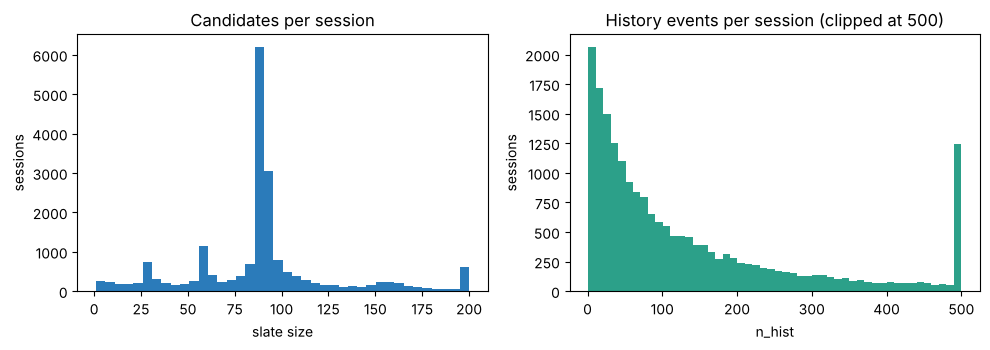

sessions with n_hist == 0: 0 | n_hist <= 2: 459


In [11]:
sess_saved = pd.read_parquet(OUT / "sessions.parquet")
# same recipe as A.6, including the fixed CRLF line ending, so the hash is identical on every OS
membership = sess_saved[["session_id", "source_row_id", "split"]].to_csv(index=False, lineterminator="\r\n")
digest = hashlib.sha256(membership.encode()).hexdigest()
print("recomputed split fingerprint:", digest)
print("matches manifest            :", digest == manifest["split_sha256"])
print("shares by split             :", (sess_saved.split.value_counts(normalize=True).round(3)).to_dict())

display(sess_saved[["slate_size", "n_hist"]].describe().round(1))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
axes[0].hist(sess_saved.slate_size, bins=40, color="#2b7bba")
axes[0].set(title="Candidates per session", xlabel="slate size", ylabel="sessions")
axes[1].hist(sess_saved.n_hist.clip(upper=500), bins=50, color="#2ca089")
axes[1].set(title="History events per session (clipped at 500)", xlabel="n_hist", ylabel="sessions")
plt.tight_layout()
plt.show()
print("sessions with n_hist == 0:", int((sess_saved.n_hist == 0).sum()),
      "| n_hist <= 2:", int((sess_saved.n_hist <= 2).sum()))

# Summary

* Four tables for a fixed 20,000-user sample, with **complete** histories and a split decided once.
* The split fingerprint is stored in the manifest and re-checked in B.2; every later step reads the
  same `sessions.parquet`.
* The shortest histories are rare (no session has an empty history), which is why Step 7 finds no true
  cold-start users.

**Hand-off to Step 3:** `candidates`, `history`, `sessions` and `meta_subset` in the model folder.